# 3.2.- Regresión Logística

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_classification
from sklearn.linear_model import LinearRegression, LogisticRegression

## Generación de datos sintéticos para clasificación binaria

En este primer paso vamos a crear un dataset artificial con **una sola variable explicativa (`x`)** y una variable objetivo (`y`) binaria (0 o 1).  

- Usamos `make_classification` de `scikit-learn`, que nos permite generar datos de prueba para problemas de clasificación.  
- Configuración:
  - `n_samples=100`: generamos 100 observaciones.  
  - `n_features=1`: solo una característica explicativa.  
  - `n_informative=1`: la característica es informativa para diferenciar entre clases.  
  - `n_redundant=0`: no añadimos variables redundantes.  
  - `n_clusters_per_class=1`: cada clase forma un único grupo.  

El resultado es un conjunto de puntos en el eje **X**, con etiquetas `y` = 0 o 1.

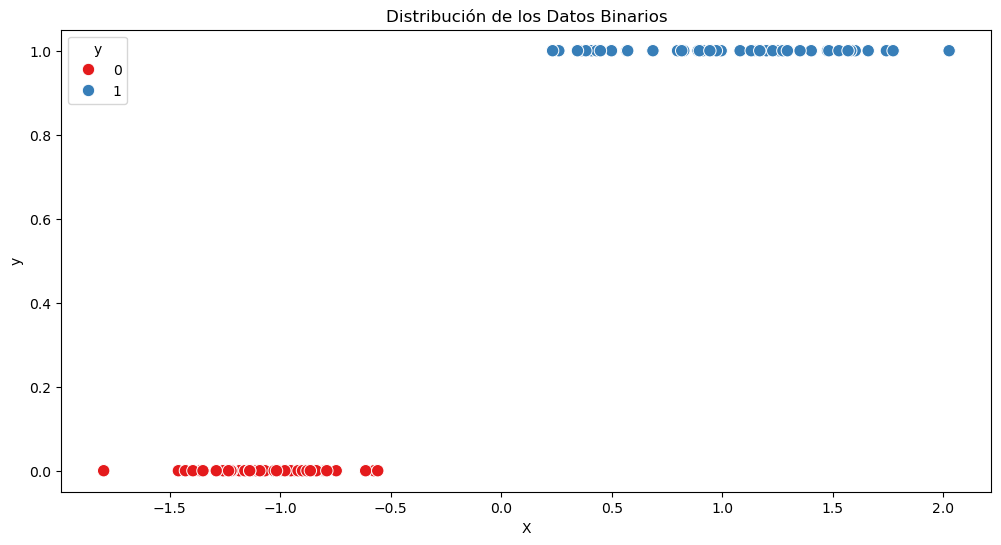

In [3]:
# Generar datos sintéticos con una sola variable explicativa
X, y = make_classification(
    n_samples=100,
    n_features=1,          # solo 1 feature
    n_informative=1,       # 1 informativa
    n_redundant=0,         # 0 redundantes
    n_clusters_per_class=1,
    random_state=32
)

# Pasamos a DataFrame
df = pd.DataFrame({"x": X.flatten(), "y": y})

plt.figure(figsize=(12,6))
sns.scatterplot(x="x", y="y", data=df, hue="y", palette="Set1", s=80)
plt.xlabel("X")
plt.title("Distribución de los Datos Binarios")
plt.show()

## Regresión Lineal aplicada a clasificación

- La regresión lineal intenta ajustar una **recta** a los datos.  
- Problema: puede devolver predicciones fuera del rango [0,1], lo cual **no tiene sentido como probabilidad**.  
- Aun así, sirve para comparar con la regresión logística.

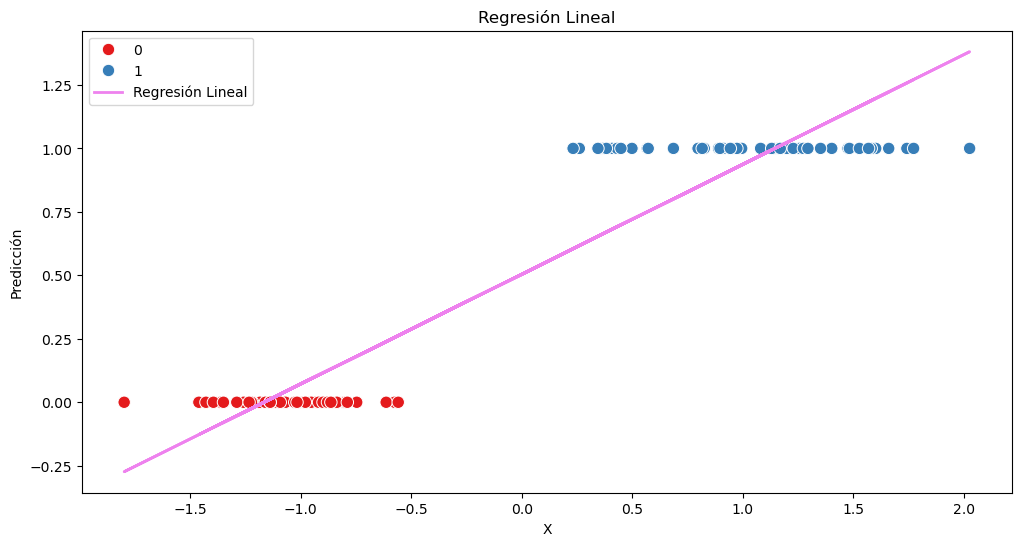

In [4]:
# Ajustar regresión lineal
lin_model = LinearRegression().fit(X, y)
y_pred_lin = lin_model.predict(X)

# Dibujar la recta de regresión lineal
plt.figure(figsize=(12,6))
sns.scatterplot(x="x", y="y", data=df, hue="y", palette="Set1", s=80)
plt.plot(X, y_pred_lin, color="violet", linewidth=2, label="Regresión Lineal")
plt.title("Regresión Lineal")
plt.xlabel("X")
plt.ylabel("Predicción")
plt.legend()
plt.show()

## Regresión Logística

La regresión logística transforma la salida lineal en una **probabilidad** usando la función **sigmoide**:

$$
p(x) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x)}}
$$

donde:

- $p(x)$ es la probabilidad estimada de que la observación pertenezca a la **clase 1**.  
- $\beta_0$ es el intercepto.  
- $\beta_1$ es el coeficiente asociado a la variable $x$.  

Esto asegura que las predicciones estén siempre en el rango $[0,1]$, lo que hace que el modelo sea ideal para **problemas de clasificación binaria**.

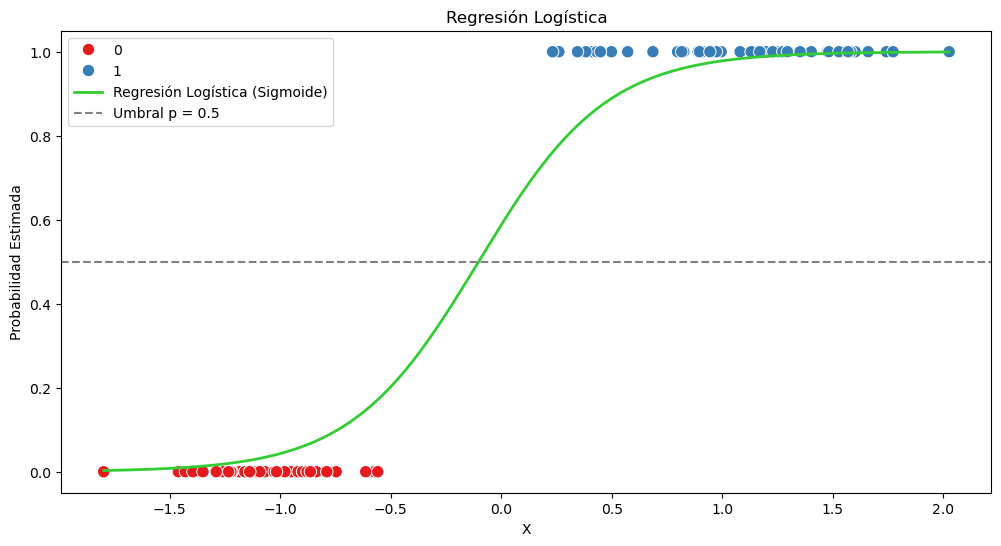

In [15]:
# Ajustar regresión logística
log_model = LogisticRegression().fit(X, y)

# Probabilidades para la clase positiva
x_range = np.linspace(X.min(), X.max(), 300).reshape(-1,1)
y_sigmoid = log_model.predict_proba(x_range)[:,1]

# Dibujar curva sigmoide
plt.figure(figsize=(12,6))
sns.scatterplot(x="x", y="y", data=df, hue="y", palette="Set1", s=80)
plt.plot(x_range, y_sigmoid, color="limegreen", linewidth=2, label="Regresión Logística (Sigmoide)")
plt.axhline(0.5, color="grey", linestyle="--", label="Umbral p = 0.5")
plt.title("Regresión Logística")
plt.xlabel("X")
plt.ylabel("Probabilidad Estimada")
plt.legend()
plt.show()

## Comparación: Regresión Lineal vs Logística

En este gráfico mostramos simultáneamente:

- La recta de la **Regresión Lineal** (que puede predecir valores fuera de [0,1]).  
- La curva de la **Regresión Logística** (sigmoide, que siempre se mantiene en [0,1]).  

Esto deja claro por qué la regresión logística es más adecuada para clasificación.

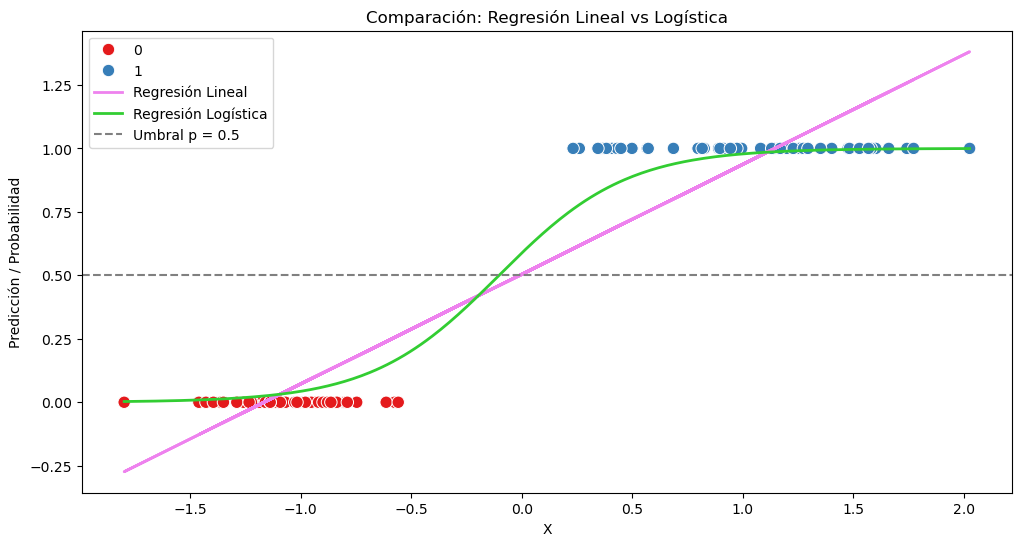

In [6]:
plt.figure(figsize=(12,6))
sns.scatterplot(x="x", y="y", data=df, hue="y", palette="Set1", s=80)
plt.plot(X, y_pred_lin, color="violet", linewidth=2, label="Regresión Lineal")
plt.plot(x_range, y_sigmoid, color="limegreen", linewidth=2, label="Regresión Logística")
plt.axhline(0.5, color="grey", linestyle="--", label="Umbral p = 0.5")
plt.title("Comparación: Regresión Lineal vs Logística")
plt.xlabel("X")
plt.ylabel("Predicción / Probabilidad")
plt.legend()
plt.show()